## Chargement et Analyse exploratoire des données 

In [ ]:
import pandas as pd

df = pd.read_csv("../data/raw/student_mental_health.csv")

In [54]:
df.shape

(2000, 17)

In [55]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [57]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [58]:
df.isna().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [66]:
df.isna().mean() * 100

Student_ID                        0.000000
Age                               0.000000
Gender                            0.000000
Year_of_Study                     0.000000
Sleep_Hours                       3.005604
Study_Hours_Per_Week              0.000000
GPA                               1.884870
Social_Media_Hours                2.954661
Screen_Time_Hours                 0.000000
Physical_Activity                 0.000000
Financial_Stress                  4.635762
Family_Support                    2.750891
Attendance_Rate                   2.343352
Part_Time_Job                     0.000000
Diet_Quality                      3.413143
Previous_Mental_Health_History    0.000000
Mental_Health_Risk                0.000000
dtype: float64

In [59]:
df.duplicated().sum()

np.int64(0)

In [60]:
df["Mental_Health_Risk"].value_counts(normalize=True)  

Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64

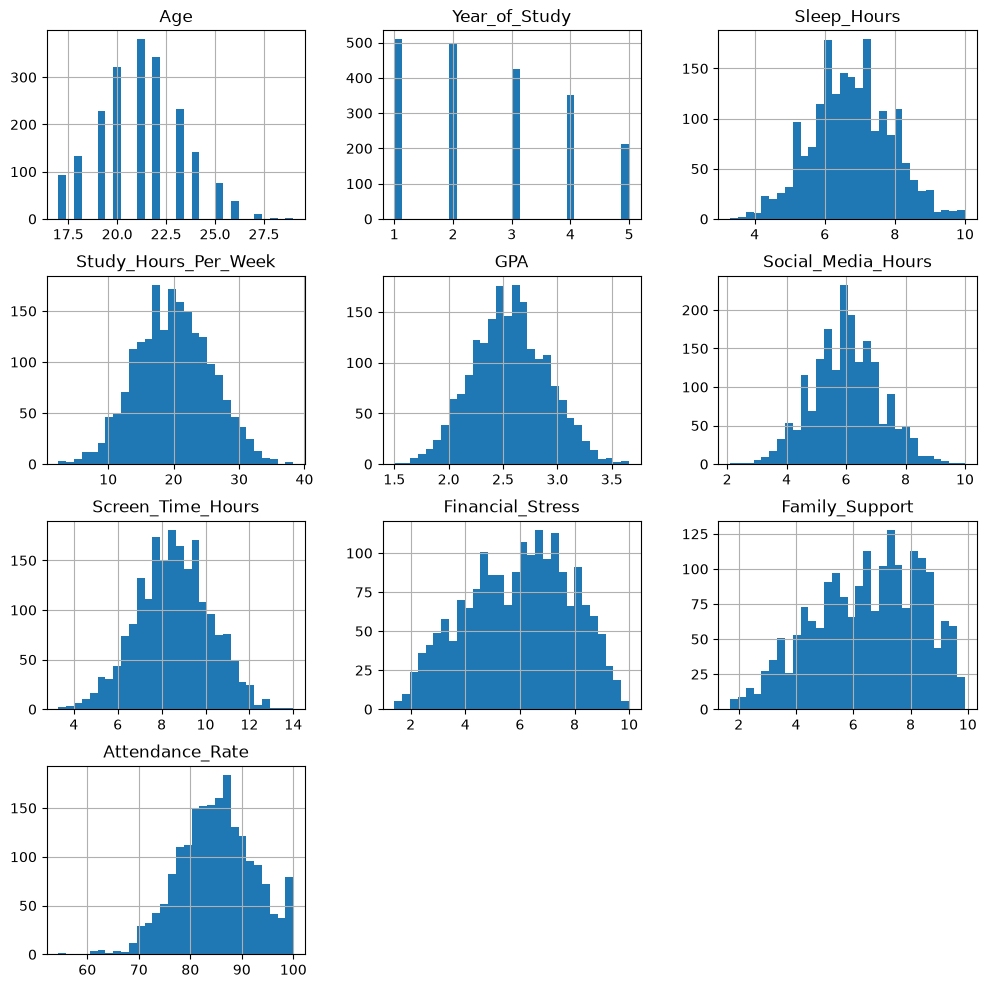

In [61]:
import matplotlib.pyplot as plt

df.hist(figsize=(12, 12), bins=30)
plt.show()

In [62]:
df.skew(numeric_only=True)

Age                     0.200876
Year_of_Study           0.314226
Sleep_Hours             0.051094
Study_Hours_Per_Week    0.039271
GPA                     0.087445
Social_Media_Hours      0.092598
Screen_Time_Hours      -0.044073
Financial_Stress       -0.168759
Family_Support         -0.304270
Attendance_Rate        -0.116483
dtype: float64

From the histograms I noticed that all features are symetrics

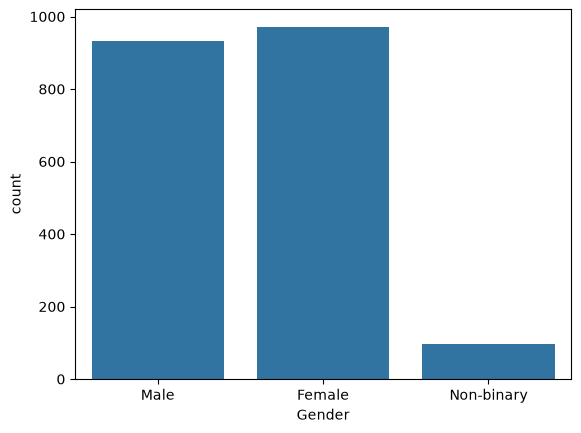

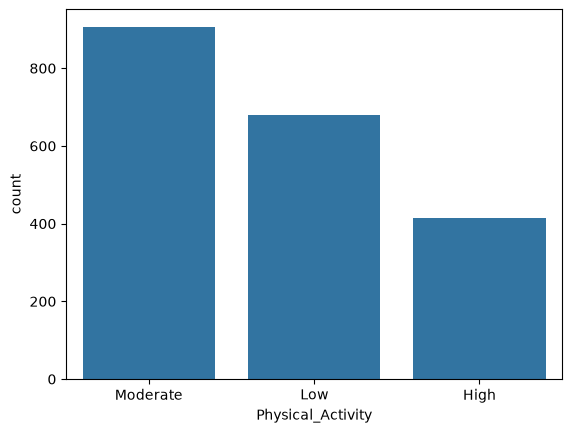

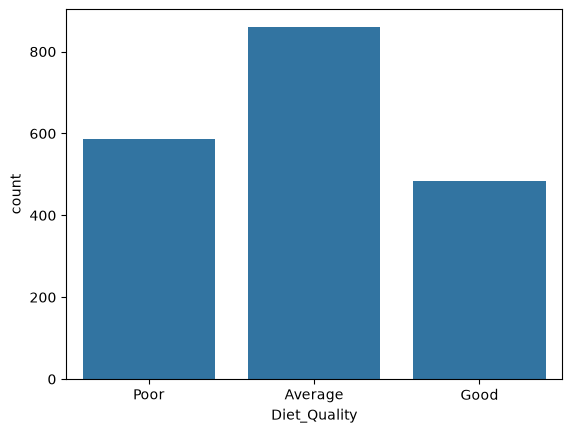

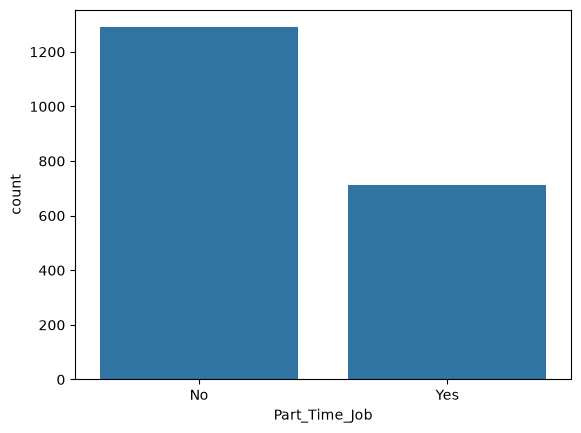

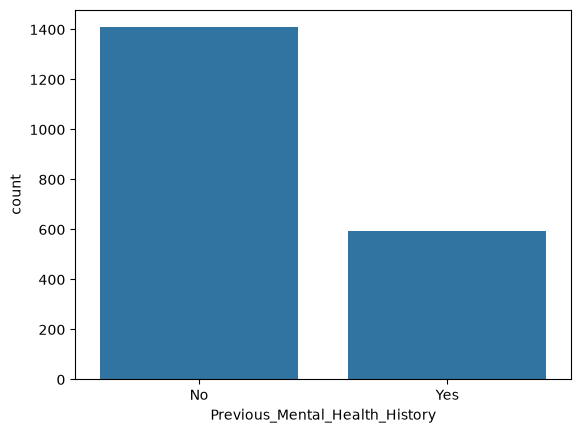

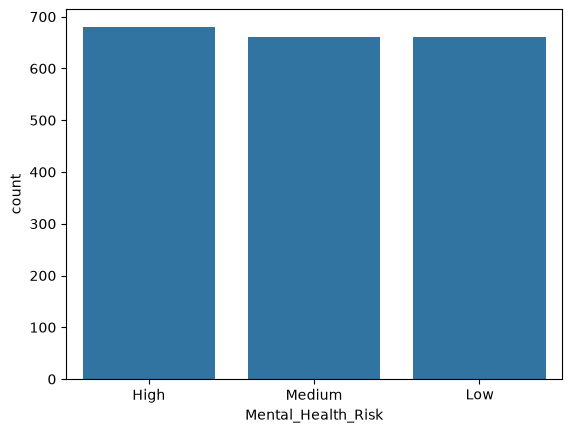

In [63]:
import seaborn as sns

categorial_cols = df[["Gender", "Physical_Activity", "Diet_Quality", "Part_Time_Job", "Previous_Mental_Health_History", "Mental_Health_Risk"]]


for col in categorial_cols.columns:
    sns.countplot(data=categorial_cols, x=col)
    plt.show()


the labels look clean and the target classes are balanced so no SMOTE needed

In [64]:
mask = df["Social_Media_Hours"] > df["Screen_Time_Hours"] 
mask.sum()

np.int64(37)

37 students have more social media hours than their screen time which is impossible since social media is part of screen time 

In [65]:
df = df[~mask]

I've dropped those 37 raw because we can't know which freature is wrong (Social_Media_Hours or Screen_Time_Hours)

In [71]:
num_cols = ["Age", "Year_of_Study", "Sleep_Hours", "Study_Hours_Per_Week", "GPA", "Social_Media_Hours", "Screen_Time_Hours", "Financial_Stress","Family_Support", "Attendance_Rate"]

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_outliers} outliers, limits [{low:.1f}, {high:.1f}]")
    outliers = df.loc[(df[col] < low) | (df[col] > high), col]
    if len(outliers) > 0:
        print("   values:", sorted(outliers.values))

Age: 3 outliers, limits [15.5, 27.5]
   values: [np.int64(28), np.int64(28), np.int64(28)]
Year_of_Study: 0 outliers, limits [-3.5, 8.5]
Sleep_Hours: 2 outliers, limits [3.6, 10.0]
   values: [np.float64(3.3), np.float64(3.6)]
Study_Hours_Per_Week: 7 outliers, limits [4.0, 36.0]
   values: [np.float64(2.4), np.float64(2.7), np.float64(3.2), np.float64(3.6), np.float64(3.9), np.float64(37.5), np.float64(38.3)]
GPA: 9 outliers, limits [1.6, 3.5]
   values: [np.float64(1.5), np.float64(1.6), np.float64(3.51), np.float64(3.51), np.float64(3.53), np.float64(3.57), np.float64(3.6), np.float64(3.64), np.float64(3.66)]
Social_Media_Hours: 19 outliers, limits [3.0, 8.9]
   values: [np.float64(2.1), np.float64(2.4), np.float64(2.4), np.float64(2.8), np.float64(2.9), np.float64(9.0), np.float64(9.0), np.float64(9.0), np.float64(9.0), np.float64(9.1), np.float64(9.2), np.float64(9.2), np.float64(9.3), np.float64(9.4), np.float64(9.4), np.float64(9.4), np.float64(9.5), np.float64(10.0), np.float64(

IQR flags a lot multiple values but all of them are possible

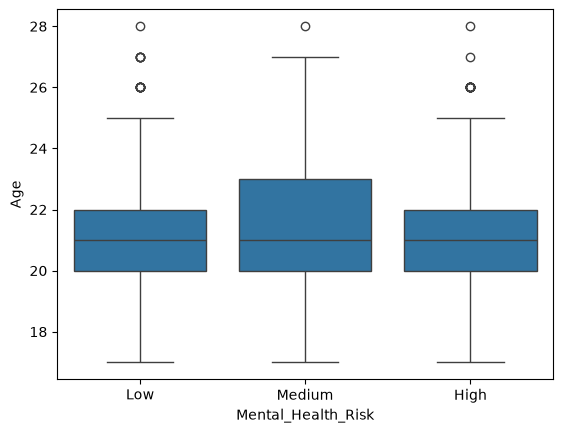

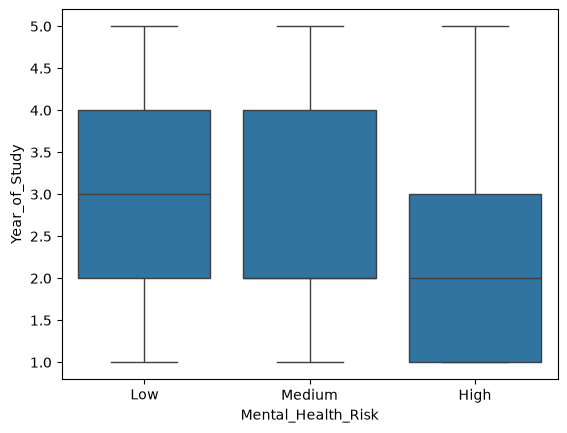

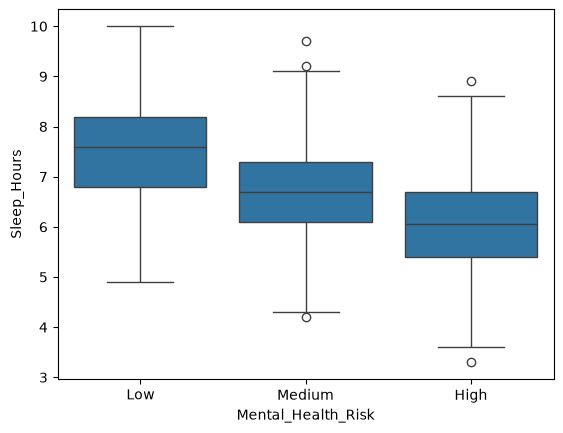

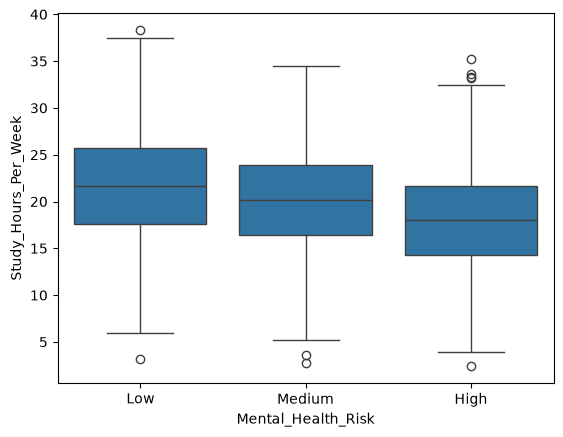

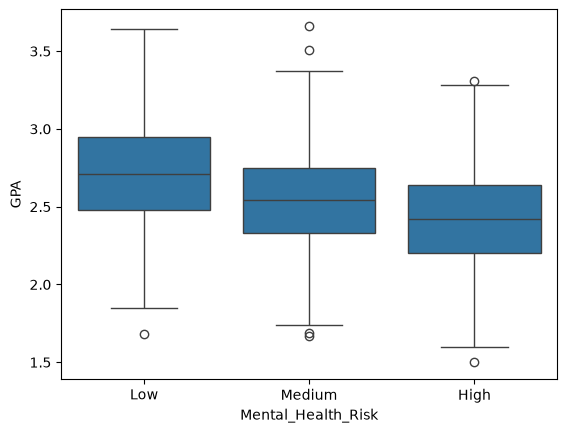

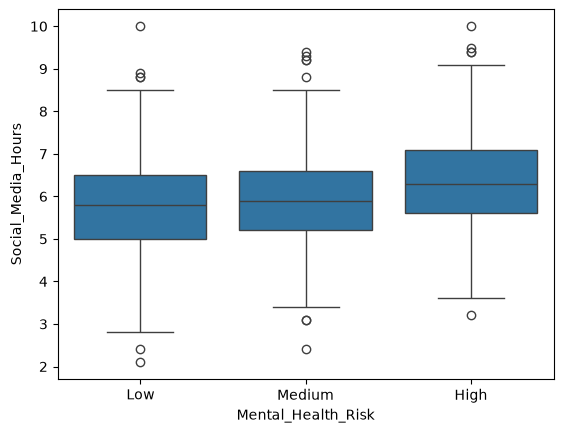

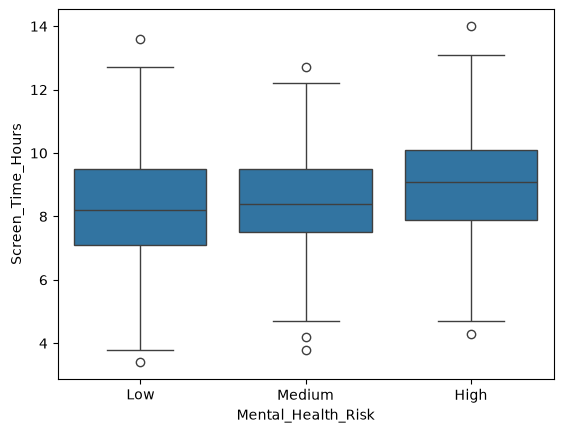

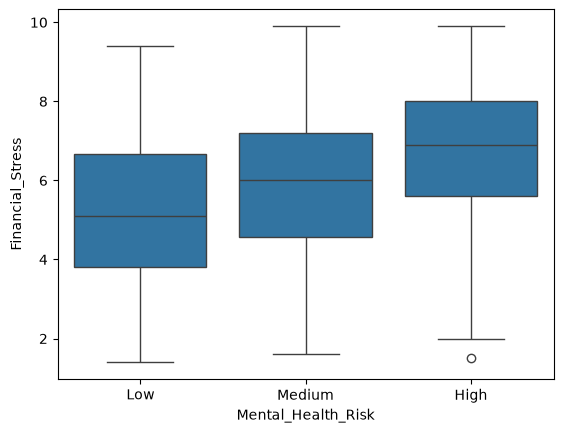

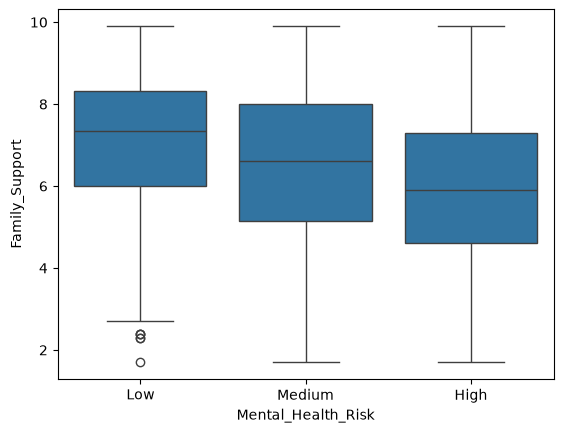

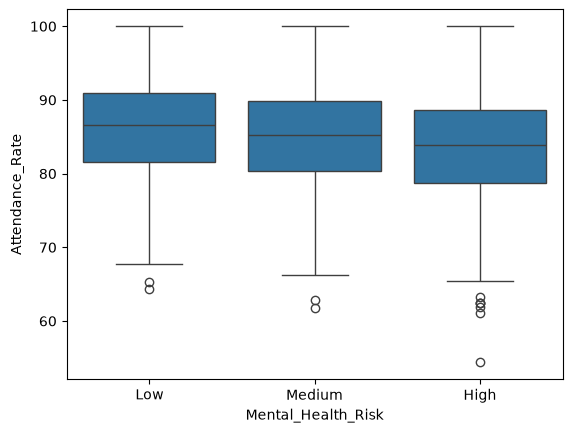

In [73]:
for col in num_cols:
    sns.boxplot(data=df, x=df["Mental_Health_Risk"], y=df[col], order=["Low", "Medium", "High"])
    plt.show()

##### less sleep hours <==> more mental health risk
##### more social media hours / screen time <==> more mental health risk
##### less study hours <==> more mental health risk
##### less GPA <==> more mental health risk
##### more financial stress <==> more mental health risk
##### less family support <==> more mental health risk

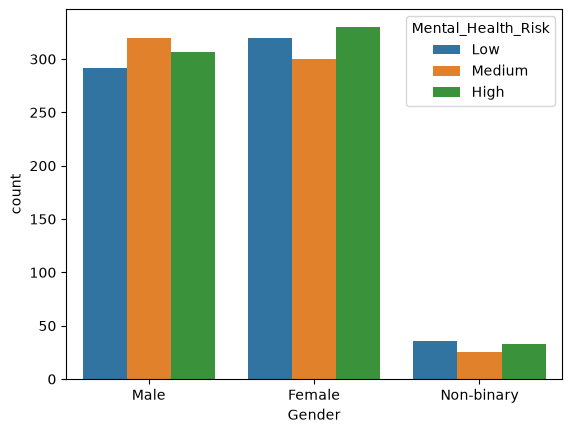

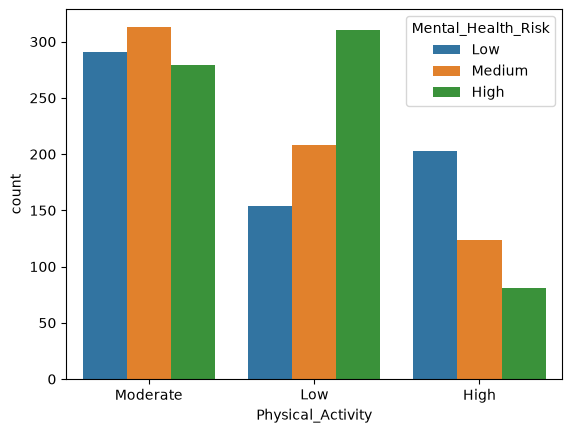

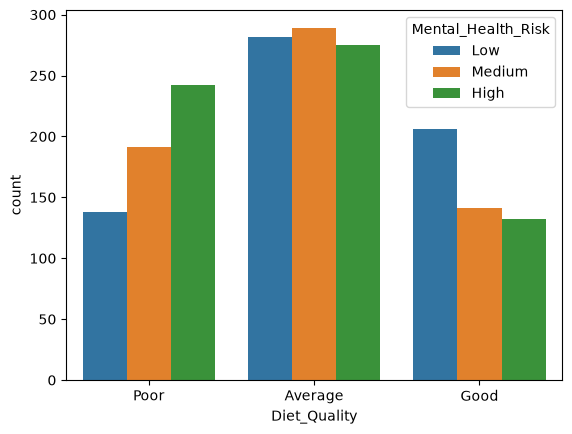

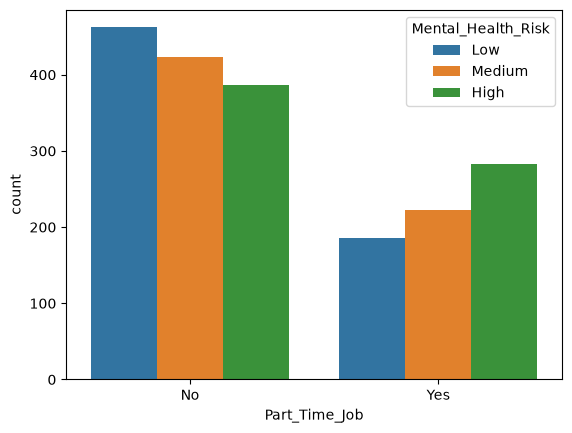

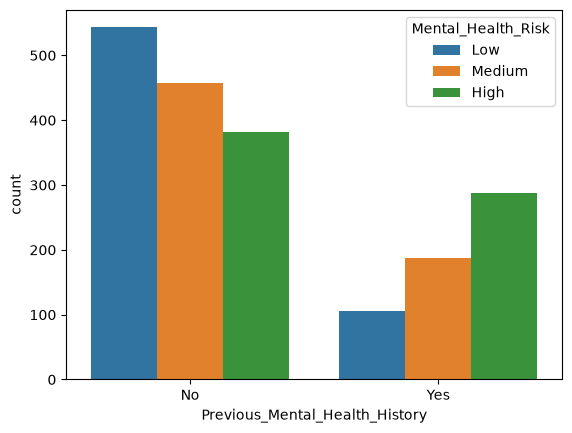

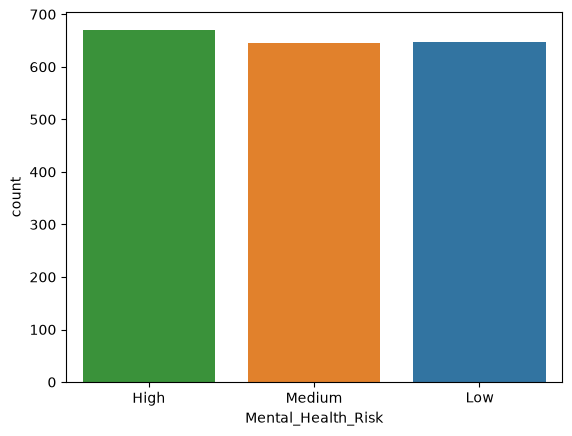

In [78]:
for col in categorial_cols:
    sns.countplot(data=df, x=df[col], hue="Mental_Health_Risk", hue_order=["Low", "Medium", "High"])
    plt.show()

##### low activity <==> more mental health risk
##### poor diet quality <==> more mental health risk
##### previous mental health history <==> more mental health risk
##### part time job <==> more mental health risk

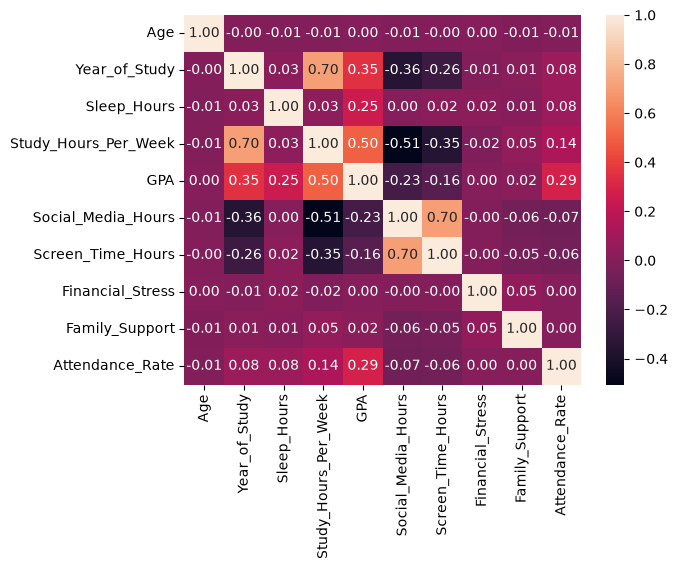

In [79]:
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f")
plt.show()

There is no strong relation between features (> 0.8) 
##### Year of study <-> Study hours per week : we can assume that students in later years study more
##### Screen time hours <-> Social media hours : it's part of it so that's normal
##### Study hours per week <-> Social media hours : more study hours less social media hours
##### Study hours per week <-> GPA : more study hours per week better GPA 

## Transformation et préparation des données

In [81]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=77)

In [90]:
import numpy as np
from sklearn.impute import SimpleImputer

imp = SimpleImputer(strategy="median")

X_train_num = imp.fit_transform(X_train[num_cols]) 
X_test_num = imp.transform(X_test[num_cols])
print(imp.statistics_)

print(np.isnan(X_train_num).sum(), np.isnan(X_test_num).sum())


[21.    2.    6.7  19.9   2.56  6.    8.5   6.1   6.7  85.  ]
0 0


In [96]:
cat_cols = ["Gender", "Physical_Activity", "Diet_Quality", "Part_Time_Job", "Previous_Mental_Health_History"]

imp = SimpleImputer(strategy="most_frequent")

X_train_cat = imp.fit_transform(X_train[cat_cols])
X_test_cat = imp.transform(X_test[cat_cols])

print(imp.statistics_)

print(pd.isna(X_train_cat).sum(), pd.isna(X_test_cat).sum())


['Female' 'Moderate' 'Average' 'No' 'No']
0 0
